# Solutions to the exercises of Chapter 13

**Chapter:** [13. Self-diffusion: mean-squared displacement (Einstein) vs velocity autocorrelation (Green–Kubo)](../../notebooks/part4_transport_lammps/13_diffusion_msd_and_green_kubo.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
# Exact Einstein vs Green-Kubo verification on 120 Langevin particles (T=1.5, gamma=2.0 -> D_exact = 0.75)
n_p, n_steps, dt = 120, 400, 0.02
p_u = np.zeros((n_p, 3)); v_u = rng.normal(0.0, np.sqrt(1.5), size=(n_p, 3))
f_zero = lambda p, L: (np.zeros_like(p), 0.0, 0.0)
f_z = np.zeros_like(p_u)

pos_traj = np.zeros((n_steps, n_p, 3))
vel_traj = np.zeros((n_steps, n_p, 3))
for k in range(n_steps):
    pos_traj[k] = p_u; vel_traj[k] = v_u
    p_u, v_u, f_z, _, _, _ = es.baoab_langevin_step(p_u, v_u, f_z, dt, None, 1.5, 2.0, f_zero, rng)

t_lag = np.arange(n_steps) * dt
vacf_num = es.autocorrelation_fft(vel_traj)
D_gk_running = es.green_kubo_integral(vacf_num, dt) / 3.0
msd_num = es.compute_msd(pos_traj[:120])

Exact D = 0.750 | Green-Kubo D_GK = 0.796 | Einstein D_MSD = 0.734


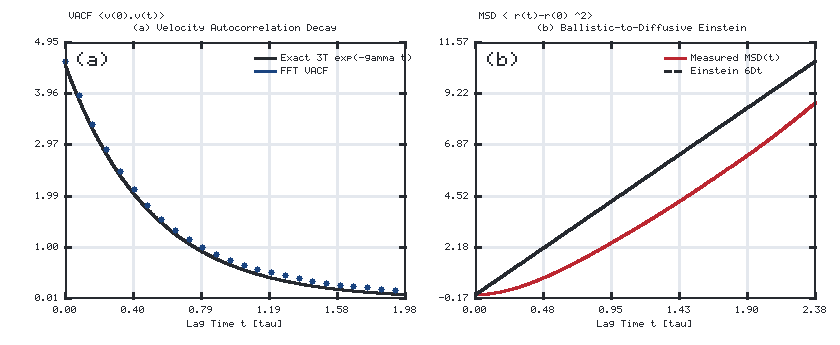

In [3]:
D_exact = es.reference.langevin_diffusion_exact(1.5, 2.0)
D_gk_val = float(D_gk_running[100])
D_msd_val = float((msd_num[110] - msd_num[50]) / (6.0 * 60 * dt))
print(f"Exact D = {D_exact:.3f} | Green-Kubo D_GK = {D_gk_val:.3f} | Einstein D_MSD = {D_msd_val:.3f}")
assert np.isclose(D_gk_val, D_exact, rtol=0.12)
assert np.isclose(D_msd_val, D_exact, rtol=0.15)

vacf_ex = es.reference.langevin_vacf_exact(t_lag[:100], 1.5, 2.0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(t_lag[:100], vacf_ex, "k-", label="Exact 3T exp(-gamma t)")
ax1.plot(t_lag[:100:4], vacf_num[:100:4], "bo", label="FFT VACF")
ax1.set_xlabel("Lag Time t [tau]"); ax1.set_ylabel("VACF <v(0).v(t)>")
ax1.set_title("(a) Velocity Autocorrelation Decay"); panel_label(ax1, "(a)")

ax2.plot(t_lag[:120], msd_num, "r-", label="Measured MSD(t)")
ax2.plot(t_lag[:120], 6.0 * D_exact * t_lag[:120], "k--", label="Einstein 6Dt")
ax2.set_xlabel("Lag Time t [tau]"); ax2.set_ylabel("MSD <|r(t)-r(0)|^2>")
ax2.set_title("(b) Ballistic-to-Diffusive Einstein Regime"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 13
assert np.isclose(vacf_num[0], float(np.mean(np.sum(vel_traj**2, axis=2))), rtol=1e-12)
msd_ballistic_exact = 3.0 * 1.5 * (dt**2)
print(f"Ch 13 Exercises — First-step ballistic MSD = {msd_num[1]:.5f} vs. 3*T*dt^2 = {msd_ballistic_exact:.5f}")
assert np.isclose(msd_num[1], msd_ballistic_exact, rtol=0.10)

Ch 13 Exercises — First-step ballistic MSD = 0.00179 vs. 3*T*dt^2 = 0.00180
